# Question 1: Load, audit and explore

The output of this notebook is a cleaned table and a written record of every
change made to produce it. Questions 2, 3 and 4 all start from that same table,
which is why the cleaning lives in `csc1105.py` rather than here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import csc1105 as cs

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.4


## 1(a) Describe the simulation and the fraud label

This part is written rather than computed. It rests on the Data in Brief
article (doi:10.1016/j.dib.2025.111534) and on three points:

1. The records come from MoMTSim, a multi-agent simulator calibrated so the
   simulated transactions reproduce the statistical qualities of real data.
2. `step` is simulation time: one step is one hour, not a calendar date.
3. `isFraud` is attached by the simulator. It marks transactions *generated* by
   a modelled fraudulent behaviour, not ones *detected* by an investigator.

## 1(b) Structure, types, missing values, duplicates, invalid labels

In [2]:
df = cs.load_raw()
print("rows, columns:", df.shape)
df.dtypes

rows, columns: (1720181, 10)


step                  int32
transactionType    category
amount              float64
initiator            string
oldBalInitiator     float64
newBalInitiator     float64
recipient            string
oldBalRecipient     float64
newBalRecipient     float64
isFraud               int64
dtype: object

In [3]:
df.head()

,step,transactionType,amount,initiator,oldBalInitiator,newBalInitiator,recipient,oldBalRecipient,newBalRecipient,isFraud
0,0,TRANSFER,19824.96,4537027967639631,187712.18,167887.22,4875702729424478,8.31,19833.27,1
1,0,PAYMENT,598.97,4296267625767470,8.92,8.92,25-0000401,0.00,0.00,0
2,0,PAYMENT,545.85,4178224023847746,93.60,-452.25,13-0001587,0.00,545.85,0
3,0,TRANSFER,19847.01,4178224023847746,-452.25,-20299.26,4096920916696293,4011.72,23858.74,1
4,0,PAYMENT,546.89,4779013371563747,159148.76,158601.88,75-0003564,0.00,546.89,0


In [4]:
# every figure Question 1(b) asks for, computed on the RAW table
a = cs.audit(df)
print("rows                 :", f"{a['rows']:,}")
print("columns              :", a["columns"])
print("rows with any missing:", f"{a['rows_with_any_missing']:,}")
print("exact duplicate rows :", f"{a['exact_duplicates']:,}")
print("isFraud values       :", a["fraud_label_values"])
print()
print("missing by column:");       print(a["missing_by_column"])
print()
print("transaction types:");       print(a["transaction_types"])

rows                 : 1,720,181
columns              : 10
rows with any missing: 0
exact duplicate rows : 0
isFraud values       : [1, 0]

missing by column:
step               0
transactionType    0
amount             0
initiator          0
oldBalInitiator    0
newBalInitiator    0
recipient          0
oldBalRecipient    0
newBalRecipient    0
isFraud            0
dtype: int64

transaction types:
transactionType
PAYMENT       667245
TRANSFER      569328
DEPOSIT       384431
WITHDRAWAL     93785
DEBIT           5392
Name: count, dtype: int64


The transaction type names printed above are used exactly as they appear in
the data rather than assumed. They become the columns of the count matrix in
Question 3.

### Negative balances

The assignment asks that these be **investigated before** any decision to remove
them. If they sit mostly in one transaction type, that is how the simulator
handles that type. If their fraud rate differs sharply from the overall rate,
removing them would also remove part of the fraud.

In [5]:
nb = cs.negative_balance_report(df)
print("rows with a negative balance:", f"{nb['rows_with_negative_balance']:,}",
      f"({nb['share_of_all_rows']:.4%} of all rows)")
print("fraud rate among them       :", f"{nb['fraud_rate_among_them']:.5f}")
print("fraud rate overall          :", f"{nb['fraud_rate_overall']:.5f}")
print()
print("by transaction type:"); print(nb["by_transaction_type"])

rows with a negative balance: 48,213 (2.8028% of all rows)
fraud rate among them       : 0.12797
fraud rate overall          : 0.10203

by transaction type:
transactionType
PAYMENT       23118
TRANSFER      20429
DEPOSIT        4245
WITHDRAWAL      218
DEBIT           203
Name: count, dtype: int64


### Apply the decisions

The decisions live in `csc1105.py`; this cell applies them. The printed record
is the reconciliation of the cleaning table in the report: start at the original
count, subtract what is listed, and the result is the final count.

In [6]:
analysis_df = cs.load_clean()
print()
print("analysis_df shape:", analysis_df.shape)

  rows before cleaning                   1,720,181
  exact duplicates removed                       0
  rows dropped for missing values                0
  rows dropped for invalid labels                0
  rows dropped for negative balances             0
  rows after cleaning                    1,720,181

analysis_df shape: (1720181, 10)


## 1(c) Transaction-type summary

In [7]:
summary = (analysis_df
           .groupby("transactionType", observed=True)
           .agg(count=("amount", "size"),
                total=("amount", "sum"),
                median=("amount", "median"),
                fraud=("isFraud", "sum"),
                fraud_rate=("isFraud", "mean"))
           .sort_values("count", ascending=False))
summary

,count,total,median,fraud,fraud_rate
transactionType,,,,,
PAYMENT,667245,1.081122e+09,595.68,0,0.00000
TRANSFER,569328,2.379688e+10,19703.97,175518,0.30829
DEPOSIT,384431,5.326466e+10,131906.56,0,0.00000
WITHDRAWAL,93785,1.219607e+10,126878.18,0,0.00000
DEBIT,5392,3.730875e+07,4915.73,0,0.00000


The fraud rate is the mean of a 0/1 column, so it equals (fraud count) / (group
size). The count is reported beside the rate, because 0.04 in a group of 150 is a
different statement from 0.04 in a group of 150,000.

Two comparisons follow from the summary: whether ranking by **count** and by
**total value** give different answers, and how the overall fraud rate compares
with the worst individual type.

In [8]:
print("ranked by transaction count:"); print(summary["count"].sort_values(ascending=False))
print()
print("ranked by total value      :"); print(summary["total"].sort_values(ascending=False))
print()
print("overall fraud rate         :", f"{analysis_df['isFraud'].mean():.5f}")
print("mean amount / median amount:",
      f"{analysis_df['amount'].mean():,.2f} / {analysis_df['amount'].median():,.2f}")

ranked by transaction count:
transactionType
PAYMENT       667245
TRANSFER      569328
DEPOSIT       384431
WITHDRAWAL     93785
DEBIT           5392
Name: count, dtype: int64

ranked by total value      :
transactionType
DEPOSIT       5.326466e+10
TRANSFER      2.379688e+10
WITHDRAWAL    1.219607e+10
PAYMENT       1.081122e+09
DEBIT         3.730875e+07
Name: total, dtype: float64

overall fraud rate         : 0.10203
mean amount / median amount: 52,538.68 / 17,298.25


### The two required plots

saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\type_counts.png


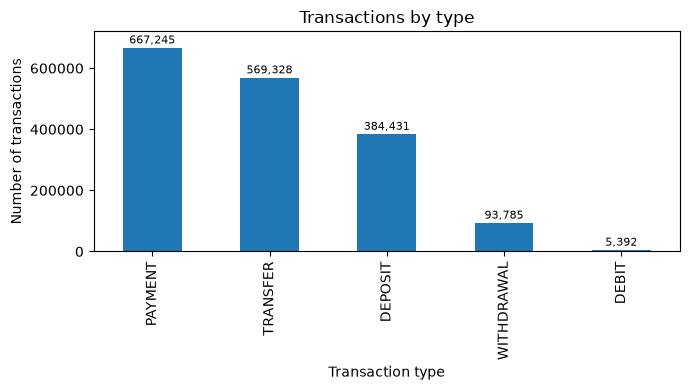

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
summary["count"].plot(kind="bar", ax=ax)
ax.set_xlabel("Transaction type")
ax.set_ylabel("Number of transactions")
ax.set_title("Transactions by type")
# label every bar, because DEBIT is under one per cent of the tallest
# bar and is otherwise invisible
for bar, value in zip(ax.patches, summary["count"]):
    ax.annotate(f"{value:,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=8)
ax.set_ylim(0, summary["count"].max() * 1.08)
cs.savefig(fig, "type_counts.png")
plt.show()

saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\amount_hist.png


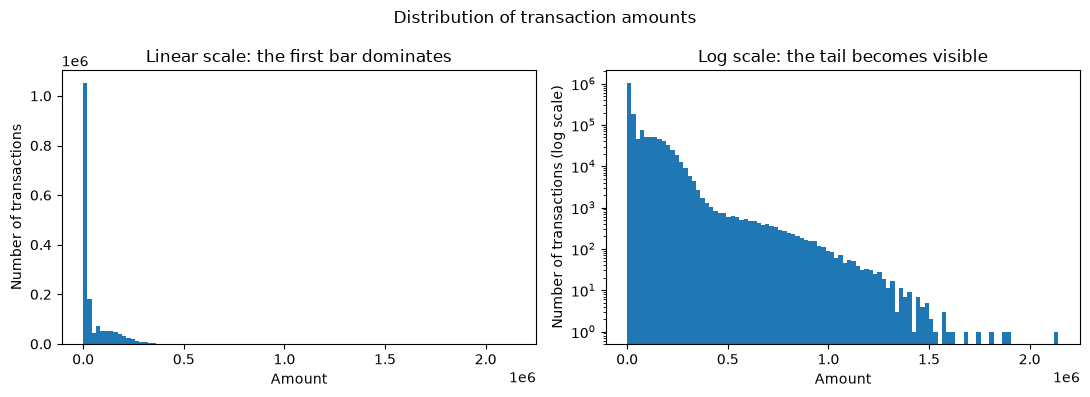

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, logy in zip(axes, (False, True)):
    ax.hist(analysis_df["amount"], bins=100)
    if logy:
        ax.set_yscale("log")
        ax.set_ylabel("Number of transactions (log scale)")
        ax.set_title("Log scale: the tail becomes visible")
    else:
        ax.set_ylabel("Number of transactions")
        ax.set_title("Linear scale: the first bar dominates")
    ax.set_xlabel("Amount")
fig.suptitle("Distribution of transaction amounts")
cs.savefig(fig, "amount_hist.png")
plt.show()

## 1(c) discussion

Three separate points follow from the summary and the two plots:

- **Skew** is about amounts. Most are small, a few are very large, so the mean
  sits above the median. Quote both and their ratio.
- **Class imbalance** is about the label. Fraud is rare, so accuracy is useless
  as a measure: calling everything legitimate scores well and finds nothing.
- **Counts are not value.** Staffing follows counts, because every transaction
  consumes handling capacity. Financial exposure follows value.